# ReLU activation comparison

Does replacing GELU or tanh with ReLU improve the five-network TGLF ensemble?
We compare four activation combinations using the same data, initial weights, and training settings.
This notebook preserves the activation comparison. GELU/ReLU has now been promoted
to the selected model in `02_nn_ensemble.ipynb`; the former GELU/tanh control is
kept in `experiments/activation_reference/`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

candidates = (
    candidate for base in (Path.cwd(), *Path.cwd().parents)
    for candidate in (base, base / "assignments/task2",
                      *(p.parent for p in sorted(base.glob("assignments/*/Task2_TGLF_surrogate.docx.pdf"))))
)
TASK2 = next(p.resolve() for p in candidates if (p / "experiments/activation_results/run_complete.json").is_file())
sys.path.insert(0, str(TASK2))
from experiments import activation_comparison as experiment
import nn_ensemble as original

RESULTS = TASK2 / 'experiments' / 'activation_results'
LABELS = experiment.LABELS
ORDER = list(LABELS)
TARGET_LABELS = {'Q_i': 'Ion heat flux', 'Q_e': 'Electron heat flux', 'Gamma_e': 'Electron particle flux'}
COLORS = ['#24587A', '#E79337', '#609F91', '#BD665C']
torch.set_num_threads(2)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'axes.titlesize': 12, 'axes.labelsize': 11})

## What changes

Each network has layers **11 → 64 → 64 → 8 → 3**. The first activation applies to both 64-unit layers;
the second applies to the 8-unit layer. The final 3-unit output remains linear in every model.

| Combination | Both 64-unit layers | 8-unit layer |
|---|---|---|
| GELU / tanh (control) | GELU | tanh |
| ReLU / tanh | ReLU | tanh |
| GELU / ReLU | GELU | ReLU |
| ReLU / ReLU | ReLU | ReLU |

All four use the same five seeds (42–46), matching initial weights for each seed, minibatch order,
training cases, and train-fitted scalers. We train on standardized `log10(Q_i)`, `log10(Q_e)`, and
`Gamma_e`, then average the five predictions **after converting back to raw flux units**.

Training uses AdamW, batch size 256, weight decay 0.0001, 30 warmup epochs at learning rate 0.001,
and up to 120 further epochs at 0.003. The same validation rule selects checkpoints and stops each run.
The learning rate was previously chosen for GELU/tanh, so this tests activation replacements under
those settings. It does not find the best separately tuned version of every activation.

## Run or load the experiment

The full run trains 20 networks on DSMLP. Results and checkpoints are saved under
`experiments/activation_results/`; running this notebook normally loads them without retraining.
To repeat training, use a fresh output directory in a **DSMLP compute container**, then point `RESULTS`
to that directory. The runner refuses to overwrite an existing run.

```bash
python experiments/activation_comparison.py --output-dir experiments/activation_results_repeat --threads 4
```

The runner saves the validation ranking before evaluating the test set. We have already inspected
this test set in earlier work, so the test comparisons here are exploratory and are not a new,
untouched assessment of a model selected through these experiments.

In [2]:
if not (RESULTS / 'run_complete.json').is_file():
    raise FileNotFoundError(f'Complete the DSMLP experiment first: {RESULTS}')
plan = json.loads((RESULTS / 'experiment_plan.json').read_text())
complete = json.loads((RESULTS / 'run_complete.json').read_text())
selection = json.loads((RESULTS / 'validation_selection.json').read_text())
reproduction = json.loads((RESULTS / 'control_reproduction.json').read_text())
assert not plan['smoke_test'] and complete['test_evaluated']
for name, checksum in complete['checksums_sha256'].items():
    assert original.digest(RESULTS / name) == checksum, f'Result changed: {name}'
for name, checksum in plan['data_sha256'].items():
    assert original.digest(TASK2 / 'prepared' / name) == checksum, f'Data changed: {name}'
# Match the historical run to its frozen source, or a new run to the current source.
source_candidates = {
    'nn_ensemble.py': [TASK2 / 'nn_ensemble.py', TASK2 / 'experiments/activation_reference/nn_ensemble.py'],
    'activation_comparison.py': [TASK2 / 'experiments/activation_comparison.py',
                               TASK2 / 'experiments/activation_reference/activation_comparison.py'],
}
for name, checksum in plan['source_code_sha256'].items():
    assert any(original.digest(path) == checksum for path in source_candidates[name]), name
original.check_manifest(TASK2 / 'experiments/activation_reference/models')

members = pd.read_csv(RESULTS / 'member_summary.csv')
metrics = pd.read_csv(RESULTS / 'ensemble_metrics.csv')
member_metrics = pd.read_csv(RESULTS / 'member_metrics.csv')
predictions = pd.read_csv(RESULTS / 'ensemble_predictions.csv', float_precision='round_trip')
assert len(members) == 20 and members['parameters'].eq(5475).all()
assert members.groupby('seed')['initial_state_sha256'].nunique().eq(1).all()
assert set(members['seed']) == set(original.SEEDS)
assert members.groupby('variant')['seed'].nunique().eq(5).all()
assert metrics[['rmse_gb', 'nrmse', 'r2']].notna().all().all()
assert selection['test_evaluated_in_this_run'] is False
assert selection['selected_utc'] < complete['finished_utc']

display(pd.Series({
    'Training cases': plan['training_cases'], 'Validation cases': plan['validation_cases'],
    'Test cases': int(metrics.loc[metrics['split'].eq('test'), 'n_cases'].iloc[0]),
    'Networks trained': len(members), 'Parameters per network': 5475,
    'Compute host': plan['environment']['hostname'], 'CPU threads': plan['environment']['threads'],
    'PyTorch': plan['environment']['torch'], 'Finished (UTC)': complete['finished_utc'],
}, name='Experiment'))

Training cases                                        3496
Validation cases                                       750
Test cases                                             750
Networks trained                                        20
Parameters per network                                5475
Compute host                            rylindberg-2603589
CPU threads                                              4
PyTorch                                         2.14.1+cpu
Finished (UTC)            2026-10-24T22:49:13.125072+00:00
Name: Experiment, dtype: object

## Validation comparison

Our primary score is **mean normalized RMSE**: calculate RMSE for each target in raw flux units,
divide it by that target's standard deviation in the training set, and average the three values.
Lower is better. This prevents targets with larger scales from dominating the comparison.

The table and plot compare the **five-network averages**. RMSE is in gyro-Bohm units; R² is unitless.

,Mean NRMSE,Q_i RMSE,Q_i R²,Q_e RMSE,Q_e R²,Gamma_e RMSE,Gamma_e R²
Hidden / 8-unit activation,,,,,,,
GELU / ReLU,0.1806,15.7963,0.9680,13.1589,0.9608,4.6066,0.9636
GELU / tanh,0.1887,17.6240,0.9601,12.7625,0.9631,4.8318,0.9599
ReLU / tanh,0.1935,18.1528,0.9577,12.9300,0.9621,4.9910,0.9572
ReLU / ReLU,0.2105,18.6664,0.9553,15.6239,0.9447,5.1896,0.9538


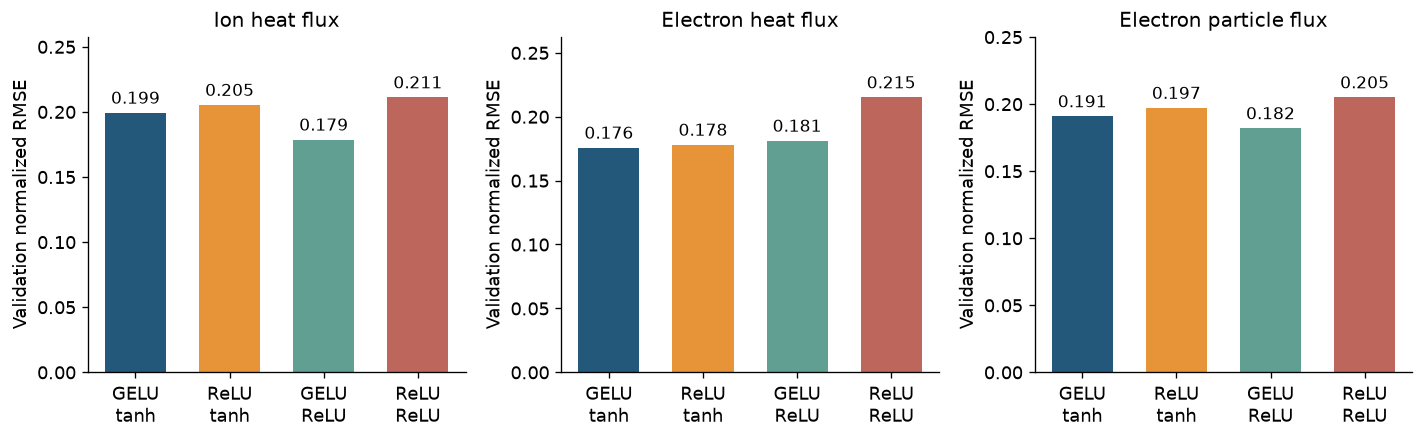

In [3]:
mean_scores = metrics.groupby(['split', 'variant'])['nrmse'].mean().unstack('split').reindex(ORDER)
validation_order = mean_scores['validation'].sort_values().index.tolist()
assert selection['selected_variant'] == validation_order[0]
for variant in ORDER:
    np.testing.assert_allclose(mean_scores.loc[variant, 'validation'], selection['validation_nrmse'][variant])

def comparison_table(split):
    rows = metrics.loc[metrics['split'].eq(split)]
    table = pd.DataFrame(index=validation_order)
    table['Mean NRMSE'] = mean_scores.loc[validation_order, split]
    for target in original.TARGETS:
        target_rows = rows.loc[rows['target'].eq(target)].set_index('variant')
        table[f'{target} RMSE'] = target_rows['rmse_gb']
        table[f'{target} R²'] = target_rows['r2']
    table.index = table.index.map(LABELS)
    table.index.name = 'Hidden / 8-unit activation'
    return table

display(comparison_table('validation').style.format('{:.4f}'))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)
for ax, target in zip(axes, original.TARGETS):
    values = metrics.query("split == 'validation' and target == @target").set_index('variant').loc[ORDER, 'nrmse']
    bars = ax.bar(range(4), values, color=COLORS, width=.65)
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=10)
    ax.set_title(TARGET_LABELS[target])
    ax.set_xticks(range(4), [LABELS[v].replace(' / ', '\n') for v in ORDER])
    ax.set_ylim(0, values.max() * 1.22)
    ax.set_ylabel('Validation normalized RMSE')
fig.tight_layout()
plt.show()

## Variation across seeds

Each alternative is paired with the GELU/tanh network that started with the same weights.
Negative differences mean the alternative had lower validation error for that seed.
These are five individual networks, not five independently trained ensembles; their spread is
not an uncertainty interval for the ensemble score.

,Mean difference,SD of differences,Seeds with lower error (of 5)
variant,,,
ReLU / tanh,+0.0200,0.0210,1
GELU / ReLU,-0.0094,0.0109,4
ReLU / ReLU,+0.0246,0.0112,0


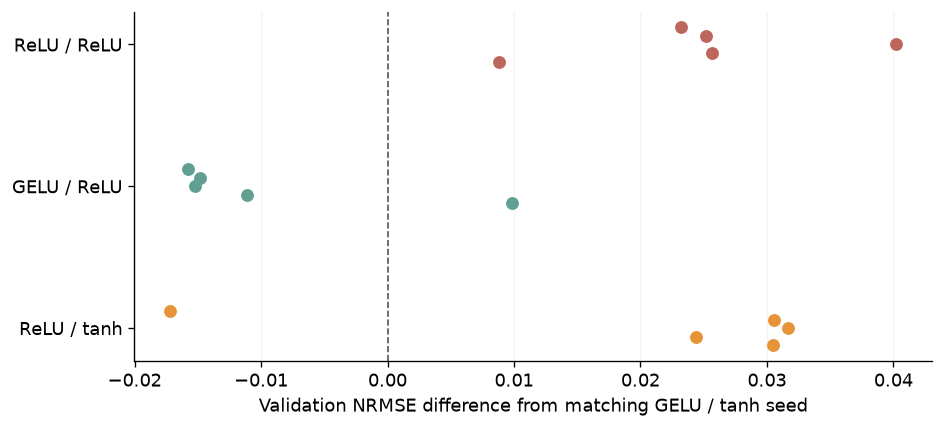

In [4]:
paired_scores = members.pivot(index='seed', columns='variant', values='validation_nrmse').reindex(columns=ORDER)
paired_differences = paired_scores.subtract(paired_scores['gelu_tanh'], axis=0).drop(columns='gelu_tanh')
paired_summary = pd.DataFrame({
    'Mean difference': paired_differences.mean(),
    'SD of differences': paired_differences.std(ddof=1),
    'Seeds with lower error (of 5)': (paired_differences < 0).sum(),
}).rename(index=LABELS)
display(paired_summary.style.format({'Mean difference': '{:+.4f}', 'SD of differences': '{:.4f}'}))
fig, ax = plt.subplots(figsize=(8, 3.7))
for j, variant in enumerate(ORDER[1:]):
    ax.scatter(paired_differences[variant], np.full(5, j) + np.linspace(-.12, .12, 5),
               color=COLORS[j+1], s=45, zorder=3)
ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
ax.set_yticks(range(3), [LABELS[v] for v in ORDER[1:]])
ax.set_xlabel('Validation NRMSE difference from matching GELU / tanh seed')
ax.grid(axis='x', alpha=.15)
fig.tight_layout()
plt.show()

## Test comparison

These are the same 750 test cases used in the earlier evaluation. The order below follows the
validation ranking. We report test results for context; the validation score determines the winner
of this experiment.

In [5]:
display(comparison_table('test').style.format('{:.4f}'))

,Mean NRMSE,Q_i RMSE,Q_i R²,Q_e RMSE,Q_e R²,Gamma_e RMSE,Gamma_e R²
Hidden / 8-unit activation,,,,,,,
GELU / ReLU,0.1536,15.5294,0.9585,11.2706,0.9646,3.2885,0.9750
GELU / tanh,0.1697,19.0780,0.9373,11.0950,0.9657,3.5523,0.9709
ReLU / tanh,0.1768,18.9843,0.9379,11.8944,0.9606,3.8413,0.9659
ReLU / ReLU,0.1821,16.9916,0.9503,14.1853,0.9440,4.0192,0.9627


## Training time

Fits ran sequentially on the same DSMLP CPU environment, alternating activation combinations within
each seed. Early stopping can produce different epoch counts. Times include training and checkpoint
work, so they describe these runs rather than the isolated cost of each activation function.

In [6]:
timing = members.groupby('variant').agg(
    ensemble_fit_seconds=('fit_seconds', 'sum'),
    mean_member_seconds=('fit_seconds', 'mean'),
    mean_continuation_epochs=('epochs_run', 'mean'),
    mean_best_continuation_epoch=('best_epoch', 'mean'),
).loc[validation_order]
display(timing.rename(index=LABELS).round(2))

,ensemble_fit_seconds,mean_member_seconds,mean_continuation_epochs,mean_best_continuation_epoch
variant,,,,
GELU / ReLU,23.30,4.66,91.0,66.0
GELU / tanh,19.85,3.97,75.0,50.0
ReLU / tanh,20.66,4.13,85.0,64.0
ReLU / ReLU,20.73,4.15,88.0,63.0


## Result checks

Check saved file hashes, recompute all ensemble scores from their saved predictions, and reload
all 20 checkpoints on a small validation sample. Also compare the fresh GELU/tanh control with the
preserved original ensemble. Small differences can occur across CPU environments; the main activation
comparison uses models trained together in this experiment.

In [7]:
data = original.load_data(TASK2 / 'prepared')
for (split, variant), frame in predictions.groupby(['split', 'variant']):
    assert len(frame) == 750 and frame['case'].is_unique
    truth = frame[[f'{t}_true' for t in original.TARGETS]].to_numpy()
    predicted = frame[[f'{t}_prediction' for t in original.TARGETS]].to_numpy()
    recalculated = pd.DataFrame(experiment.metric_rows(truth, predicted, data['raw_training_std'], variant, split)).set_index('target')
    saved = metrics.query('split == @split and variant == @variant').set_index('target')
    np.testing.assert_allclose(recalculated.loc[original.TARGETS, ['rmse_gb', 'nrmse', 'r2']],
                               saved.loc[original.TARGETS, ['rmse_gb', 'nrmse', 'r2']], rtol=1e-10, atol=1e-10)

sample_ids = data['ids']['validation'][:16]
for variant in ORDER:
    replay = []
    for seed in original.SEEDS:
        model, saved = experiment.load_member(RESULTS / 'models' / variant / f'seed{seed}' / 'checkpoint.pt')
        replay.append(original.predict(model, data['X_validation'][:16], saved)['prediction'])
    actual = original.average_predictions(replay)
    expected = predictions.query("split == 'validation' and variant == @variant").set_index('case').loc[
        sample_ids, [f'{t}_prediction' for t in original.TARGETS]].to_numpy()
    np.testing.assert_allclose(actual, expected, rtol=2e-4, atol=2e-4)

print('Passed: result hashes, preserved GELU/tanh reference, paired initial weights, metrics, and 20 checkpoint reloads.')
display(pd.Series(reproduction, name='Original ensemble vs fresh control'))

Passed: result hashes, preserved GELU/tanh reference, paired initial weights, metrics, and 20 checkpoint reloads.


old_validation_nrmse                0.188674
new_validation_nrmse                0.188674
max_absolute_flux_difference             0.0
allclose_rtol_0.0002_atol_0.0002        True
Name: Original ensemble vs fresh control, dtype: object

## Conclusion

In [8]:
winner = validation_order[0]
control = mean_scores.loc['gelu_tanh', 'validation']
fully_relu = mean_scores.loc['relu_relu', 'validation']
relative = 100 * (fully_relu / control - 1)
comparison_word = 'higher' if relative > 0 else 'lower'
lines = [
    f"**{LABELS[winner]}** has the lowest mean validation NRMSE: **{mean_scores.loc[winner, 'validation']:.4f}**.",
    f"Replacing all three nonlinear activations with ReLU gives **{fully_relu:.4f}**, "
    f"compared with **{control:.4f}** for GELU/tanh: **{abs(relative):.1f}% {comparison_word} error**.",
]
if winner == 'gelu_tanh':
    lines.append('This experiment supports keeping GELU/tanh for the current ensemble.')
else:
    gain = 100 * (1 - mean_scores.loc[winner, 'validation'] / control)
    lines.append(f"The winning combination reduces validation error by {gain:.1f}% under these settings. "
                 'Its five checkpoints are now the selected model in 02_nn_ensemble.ipynb.')
if winner != 'gelu_tanh':
    control_rows = metrics.query("split == 'validation' and variant == 'gelu_tanh'").set_index('target')
    winner_rows = metrics.query("split == 'validation' and variant == @winner").set_index('target')
    improved = [TARGET_LABELS[t].lower() for t in original.TARGETS if winner_rows.loc[t, 'rmse_gb'] < control_rows.loc[t, 'rmse_gb']]
    worsened = [TARGET_LABELS[t].lower() for t in original.TARGETS if winner_rows.loc[t, 'rmse_gb'] > control_rows.loc[t, 'rmse_gb']]
    if improved and worsened:
        lines.append('The winning combination lowers validation RMSE for ' + ' and '.join(improved)
                     + ', but raises it for ' + ' and '.join(worsened) + '.')
lines.append('This is a comparison of one fixed training setup and one data split. '
             'Separate hyperparameter tuning or new splits could change the ranking.')
display(Markdown('\n\n'.join(lines)))

**GELU / ReLU** has the lowest mean validation NRMSE: **0.1806**.

Replacing all three nonlinear activations with ReLU gives **0.2105**, compared with **0.1887** for GELU/tanh: **11.5% higher error**.

The winning combination reduces validation error by 4.3% under these settings. Its five checkpoints are now the selected model in 02_nn_ensemble.ipynb.

The winning combination lowers validation RMSE for ion heat flux and electron particle flux, but raises it for electron heat flux.

This is a comparison of one fixed training setup and one data split. Separate hyperparameter tuning or new splits could change the ranking.